In [1]:
pip install pandas numpy scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'C:\Users\araga\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [2]:
import pandas as pd
import numpy as np

# All 41 features + label + difficulty score
columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins",
    "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty"
]

train_df = pd.read_csv("KDDTrain+.txt", names=columns)
test_df = pd.read_csv("KDDTest+.txt", names=columns)

# Drop the difficulty column so the model cannot cheat
train_df.drop(columns=["difficulty"], inplace=True)
test_df.drop(columns=["difficulty"], inplace=True)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
train_df.head(3)

Train shape: (125973, 42)
Test shape: (22544, 42)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,25,0.17,0.03,0.17,0.0,0.0,0.0,0.05,0.0,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,1,0.00,0.60,0.88,0.0,0.0,0.0,0.00,0.0,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,26,0.10,0.05,0.00,0.0,1.0,1.0,0.00,0.0,neptune


In [3]:
attack_map = {
    "normal": "normal",
    # DoS attacks
    "back": "DoS", "land": "DoS", "neptune": "DoS", "pod": "DoS",
    "smurf": "DoS", "teardrop": "DoS", "mailbomb": "DoS", "apache2": "DoS",
    "processtable": "DoS", "udpstorm": "DoS",
    # Probe attacks
    "ipsweep": "Probe", "nmap": "Probe", "portsweep": "Probe",
    "satan": "Probe", "mscan": "Probe", "saint": "Probe",
    # R2L attacks
    "ftp_write": "R2L", "guess_passwd": "R2L", "imap": "R2L", "multihop": "R2L",
    "phf": "R2L", "spy": "R2L", "warezclient": "R2L", "warezmaster": "R2L",
    "sendmail": "R2L", "named": "R2L", "snmpgetattack": "R2L", "snmpguess": "R2L",
    "xlock": "R2L", "xsnoop": "R2L", "worm": "R2L", "httptunnel": "R2L",
    # U2R attacks
    "buffer_overflow": "U2R", "loadmodule": "U2R", "perl": "U2R",
    "rootkit": "U2R", "ps": "U2R", "sqlattack": "U2R", "xterm": "U2R"
}

train_df["class"] = train_df["label"].map(attack_map)
test_df["class"] = test_df["label"].map(attack_map)

# Check for any unmapped labels (both should be 0)
print("Missing train labels:", train_df["class"].isna().sum())
print("Missing test labels:", test_df["class"].isna().sum())

print("\nTraining set class counts:")
print(train_df["class"].value_counts())

print("\nTest set class counts:")
print(test_df["class"].value_counts())

Missing train labels: 0
Missing test labels: 0

Training set class counts:
class
normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Test set class counts:
class
normal    9711
DoS       7458
R2L       2887
Probe     2421
U2R         67
Name: count, dtype: int64


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder

# Separate inputs (X) from answers (y)
X_train = train_df.drop(columns=["label", "class"])
y_train_text = train_df["class"]

X_test = test_df.drop(columns=["label", "class"])
y_test_text = test_df["class"]

# Identify categorical vs numerical columns
cat_cols = ["protocol_type", "service", "flag"]
num_cols = [col for col in X_train.columns if col not in cat_cols]

# Build the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)
    ]
)

# Learn scaling/encoding rules ONLY from training data, then apply to both
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Convert text class labels ("DoS", "normal", etc.) into integers (0 to 4)
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train_text)
y_test = label_encoder.transform(y_test_text)

print("Processed X_train shape:", X_train_processed.shape)
print("Processed X_test shape:", X_test_processed.shape)
print("Class mapping:", dict(enumerate(label_encoder.classes_)))

Processed X_train shape: (125973, 122)
Processed X_test shape: (22544, 122)
Class mapping: {0: 'DoS', 1: 'Probe', 2: 'R2L', 3: 'U2R', 4: 'normal'}


In [5]:
import joblib

np.savez_compressed(
    "nsl_kdd_processed.npz",
    X_train=X_train_processed,
    y_train=y_train,
    X_test=X_test_processed,
    y_test=y_test
)

joblib.dump(preprocessor, "preprocessor.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

print("Saved successfully! Step 1 is complete.")

Saved successfully! Step 1 is complete.


In [6]:
import numpy as np
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Load the clean arrays and label encoder from Step 1
data = np.load("nsl_kdd_processed.npz")
X_train, y_train = data["X_train"], data["y_train"]
X_test, y_test = data["X_test"], data["y_test"]

label_encoder = joblib.load("label_encoder.pkl")

# Build and train the Random Forest (100 trees, using all CPU cores)
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest...")
rf_model.fit(X_train, y_train)
print("Training complete!")

Training Random Forest...
Training complete!


In [7]:
# Predict classes on the unseen test set
y_pred_rf = rf_model.predict(X_test)

# Overall metrics (weighted accounts for class sizes)
accuracy = accuracy_score(y_test, y_pred_rf)
precision = precision_score(y_test, y_pred_rf, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred_rf, average="weighted", zero_division=0)
f1_weighted = f1_score(y_test, y_pred_rf, average="weighted", zero_division=0)
f1_macro = f1_score(y_test, y_pred_rf, average="macro", zero_division=0)

print("=== RANDOM FOREST BASELINE RESULTS ===")
print(f"Accuracy:           {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision (wt):     {precision:.4f}")
print(f"Recall (wt):        {recall:.4f}")
print(f"F1-Score (wt):      {f1_weighted:.4f}")
print(f"F1-Score (macro):   {f1_macro:.4f}")

print("\n=== PER-CLASS BREAKDOWN ===")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0
))

=== RANDOM FOREST BASELINE RESULTS ===
Accuracy:           0.7519 (75.19%)
Precision (wt):     0.8104
Recall (wt):        0.7519
F1-Score (wt):      0.7060
F1-Score (macro):   0.4843

=== PER-CLASS BREAKDOWN ===
              precision    recall  f1-score   support

         DoS     0.9625    0.7993    0.8733      7458
       Probe     0.8124    0.6064    0.6944      2421
         R2L     0.9552    0.0222    0.0433      2887
         U2R     0.3333    0.0149    0.0286        67
      normal     0.6533    0.9737    0.7820      9711

    accuracy                         0.7519     22544
   macro avg     0.7434    0.4833    0.4843     22544
weighted avg     0.8104    0.7519    0.7060     22544



In [8]:
joblib.dump(rf_model, "rf_model.pkl")
np.save("y_pred_rf.npy", y_pred_rf)
print("Saved rf_model.pkl and y_pred_rf.npy!")

Saved rf_model.pkl and y_pred_rf.npy!


In [9]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'C:\Users\araga\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [11]:
import numpy as np
import joblib
import tensorflow as tf

# Fix random seeds so your results stay consistent across runs
np.random.seed(42)
tf.random.set_seed(42)

# Load saved Step 1 data
data = np.load("nsl_kdd_processed.npz")
X_train = data["X_train"].astype(np.float32)
y_train = data["y_train"]
X_test = data["X_test"].astype(np.float32)
y_test = data["y_test"]

label_encoder = joblib.load("label_encoder.pkl")

# Reshape from (samples, features) -> (samples, 1, features)
X_train_lstm = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test_lstm = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

print("Original shape:", X_train.shape)
print("LSTM train shape:", X_train_lstm.shape)
print("LSTM test shape:", X_test_lstm.shape)

Original shape: (125973, 122)
LSTM train shape: (125973, 1, 122)
LSTM test shape: (22544, 1, 122)


In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense

num_features = X_train_lstm.shape[2]   # 122
num_classes = len(label_encoder.classes_)  # 5

lstm_model = Sequential([
    Input(shape=(1, num_features)),
    LSTM(64),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

lstm_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          47,872 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 5)                   │             325 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 48,197 (188.27 KB)

 Trainable params: 48,197 (188.27 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train_lstm,
    y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.9594 - loss: 0.1826 - val_accuracy: 0.9826 - val_loss: 0.0463
Epoch 2/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9871 - loss: 0.0396 - val_accuracy: 0.9921 - val_loss: 0.0291
Epoch 3/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9905 - loss: 0.0300 - val_accuracy: 0.9933 - val_loss: 0.0245
Epoch 4/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9920 - loss: 0.0261 - val_accuracy: 0.9938 - val_loss: 0.0222
Epoch 5/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9925 - loss: 0.0236 - val_accuracy: 0.9944 - val_loss: 0.0205
Epoch 6/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.9933 - loss: 0.0218 - val_accuracy: 0.9942 - val_loss: 0.0195
Epoch 7/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9938 - loss: 0.0206 - val_accuracy: 0.9946 - val_loss: 0.0181
Epoch 8/20
788/788 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9939 - loss: 0.0192 - val_accura

In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict probabilities for all 5 classes, then pick the highest one per row
y_pred_probs = lstm_model.predict(X_test_lstm)
y_pred_lstm = np.argmax(y_pred_probs, axis=1)

accuracy = accuracy_score(y_test, y_pred_lstm)
precision = precision_score(y_test, y_pred_lstm, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred_lstm, average="weighted", zero_division=0)
f1_weighted = f1_score(y_test, y_pred_lstm, average="weighted", zero_division=0)
f1_macro = f1_score(y_test, y_pred_lstm, average="macro", zero_division=0)

print("=== LSTM RESULTS ===")
print(f"Accuracy:           {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision (wt):     {precision:.4f}")
print(f"Recall (wt):        {recall:.4f}")
print(f"F1-Score (wt):      {f1_weighted:.4f}")
print(f"F1-Score (macro):   {f1_macro:.4f}")

print("\n=== PER-CLASS BREAKDOWN ===")
print(classification_report(
    y_test,
    y_pred_lstm,
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0
))

# Save model and predictions for Steps 4 (Evaluation) and 5 (Streamlit app)
lstm_model.save("lstm_model.keras")
np.save("y_pred_lstm.npy", y_pred_lstm)
print("Saved lstm_model.keras and y_pred_lstm.npy!")

705/705 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
=== LSTM RESULTS ===
Accuracy:           0.7602 (76.02%)
Precision (wt):     0.8059
Recall (wt):        0.7602
F1-Score (wt):      0.7238
F1-Score (macro):   0.5749

=== PER-CLASS BREAKDOWN ===
              precision    recall  f1-score   support

         DoS     0.9110    0.8400    0.8741      7458
       Probe     0.8543    0.6468    0.7362      2421
         R2L     0.9600    0.0831    0.1530      2887
         U2R     0.8235    0.2090    0.3333        67
      normal     0.6672    0.9321    0.7777      9711

    accuracy                         0.7602     22544
   macro avg     0.8432    0.5422    0.5749     22544
weighted avg     0.8059    0.7602    0.7238     22544

Saved lstm_model.keras and y_pred_lstm.npy!


In [16]:
pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'C:\Users\araga\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


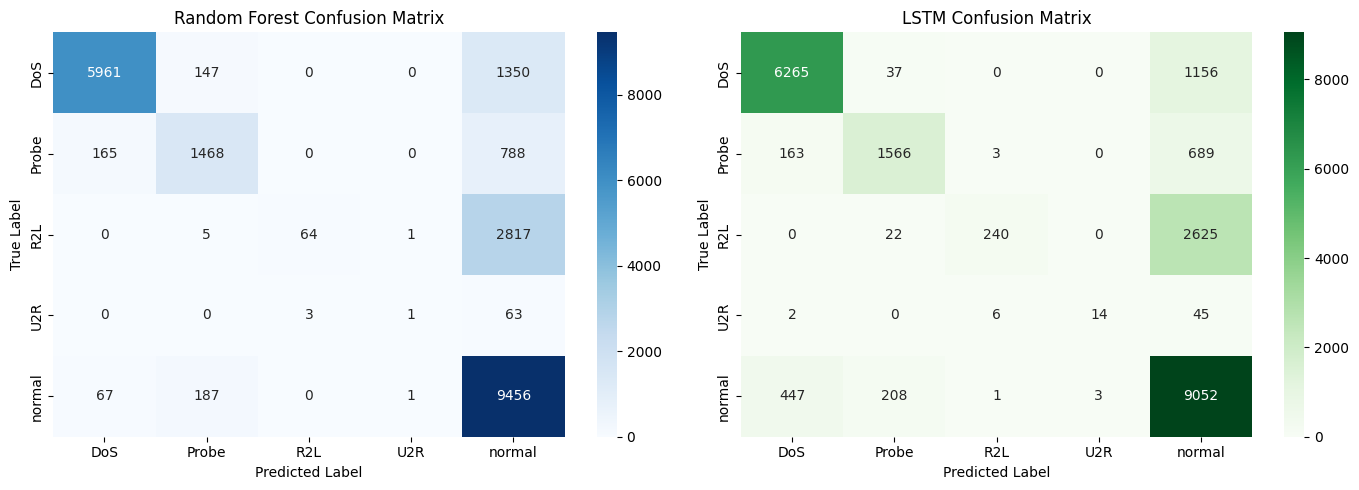

Saved confusion_matrices.png!


In [17]:
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Load test labels and predictions from Steps 1-3
data = np.load("nsl_kdd_processed.npz")
y_test = data["y_test"]
y_pred_rf = np.load("y_pred_rf.npy")
y_pred_lstm = np.load("y_pred_lstm.npy")
label_encoder = joblib.load("label_encoder.pkl")
class_names = label_encoder.classes_

cm_rf = confusion_matrix(y_test, y_pred_rf)
cm_lstm = confusion_matrix(y_test, y_pred_lstm)

# Plot both confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm_rf, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names, ax=axes[0]
)
axes[0].set_title("Random Forest Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(
    cm_lstm, annot=True, fmt="d", cmap="Greens",
    xticklabels=class_names, yticklabels=class_names, ax=axes[1]
)
axes[1].set_title("LSTM Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=150)
plt.show()
print("Saved confusion_matrices.png!")

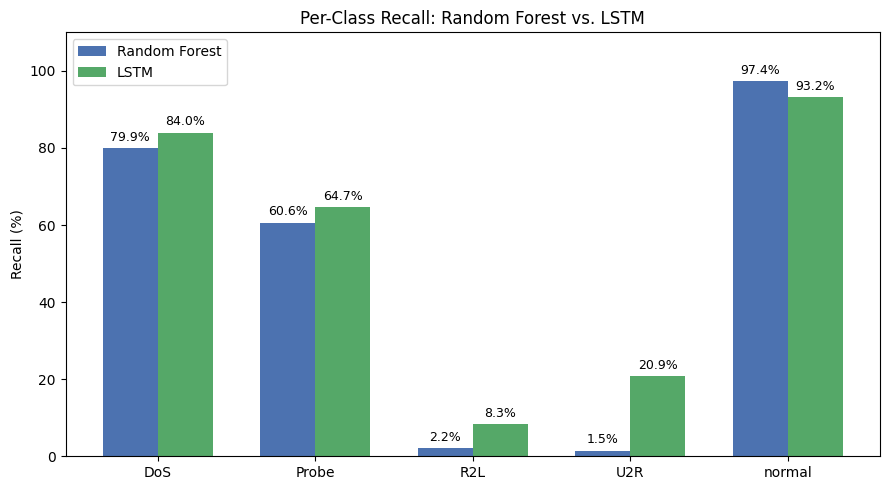


LSTM predictions for TRUE 'R2L' rows (total 2887):
  Predicted as DoS    : 0
  Predicted as Probe  : 22
  Predicted as R2L    : 240
  Predicted as U2R    : 0
  Predicted as normal : 2625

LSTM predictions for TRUE 'U2R' rows (total 67):
  Predicted as DoS    : 2
  Predicted as Probe  : 0
  Predicted as R2L    : 6
  Predicted as U2R    : 14
  Predicted as normal : 45


In [18]:
from sklearn.metrics import recall_score

recall_rf = recall_score(y_test, y_pred_rf, average=None, zero_division=0)
recall_lstm = recall_score(y_test, y_pred_lstm, average=None, zero_division=0)

# Bar chart comparing per-class recall
x = np.arange(len(class_names))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
bars1 = ax.bar(x - width/2, recall_rf * 100, width, label="Random Forest", color="#4C72B0")
bars2 = ax.bar(x + width/2, recall_lstm * 100, width, label="LSTM", color="#55A868")

ax.set_ylabel("Recall (%)")
ax.set_title("Per-Class Recall: Random Forest vs. LSTM")
ax.set_xticks(x)
ax.set_xticklabels(class_names)
ax.set_ylim(0, 110)
ax.legend()

# Put exact percentages above each bar
for bar in list(bars1) + list(bars2):
    height = bar.get_height()
    ax.annotate(f"{height:.1f}%",
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.savefig("per_class_recall.png", dpi=150)
plt.show()

# Print where missed R2L and U2R attacks actually went (LSTM)
for target_class in ["R2L", "U2R"]:
    idx = list(class_names).index(target_class)
    row = cm_lstm[idx]
    print(f"\nLSTM predictions for TRUE '{target_class}' rows (total {row.sum()}):")
    for pred_name, count in zip(class_names, row):
        print(f"  Predicted as {pred_name:<7}: {count}")

In [19]:
import pandas as pd

columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins",
    "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
    "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate", "dst_host_rerror_rate",
    "dst_host_srv_rerror_rate", "label", "difficulty"
]

sample_df = pd.read_csv("KDDTest+.txt", names=columns).sample(500, random_state=42)
# Drop the answers so it looks like real live traffic
sample_df.drop(columns=["label", "difficulty"]).to_csv("sample_traffic.csv", index=False)
print("Created sample_traffic.csv (500 rows, 41 features)!")

Created sample_traffic.csv (500 rows, 41 features)!


In [20]:
pip install streamlit

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'C:\Users\araga\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.
